# Experiment 1

In [1]:
import re
import torch
import torch.nn as nn
from collections import Counter

# 1. Dataset: Change this text to use your own corpus
text = """Natural language processing uses neural networks.
Word embeddings represent words as vectors.
Neural networks learn from context words."""

tokens = re.findall(r"\b\w+\b", text.lower())
vocab = {w: i for i, w in enumerate(Counter(tokens))}
V = len(vocab)

# 2. Generate Skip-gram training pairs
pairs = []
for i, word in enumerate(tokens):
    for j in range(max(0, i-2), min(len(tokens), i+3)):
        if i != j:
            pairs.append((vocab[word], vocab[tokens[j]]))

# 3. Define model
class Word2Vec(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(V, 50)
        self.fc = nn.Linear(50, V)

    def forward(self, x):
        return self.fc(self.emb(x))

model = Word2Vec()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

# 4. Train
for epoch in range(50):
    total_loss = 0
    for center, context in pairs:
        x = torch.tensor([center])
        y = torch.tensor([context])
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

# 5. Display embeddings
for word in ["language", "neural"]:
    print(word, model.emb.weight[vocab[word]].detach())

Epoch 10, Loss: 122.7011
Epoch 20, Loss: 118.1975
Epoch 30, Loss: 115.9825
Epoch 40, Loss: 114.6473
Epoch 50, Loss: 113.4126
language tensor([ 0.4260,  0.9926,  0.5714, -2.2021, -0.8125, -0.3743,  0.3254,  0.4131,
         1.5546, -1.0033,  0.4091, -1.5596, -0.2156,  0.1306, -1.2087, -1.0768,
        -0.4216, -0.1793,  0.2353, -0.8101, -1.1077,  0.0511,  0.1262,  0.5056,
         1.2145, -0.2656,  0.0863, -0.7150, -0.2466, -0.0658,  0.7712,  0.2092,
         1.7620, -1.1372,  0.4169, -1.3058,  0.1372, -0.2540, -1.3508,  0.2930,
         0.3063,  0.6345, -0.9255,  0.5424,  0.1470, -0.6226,  1.0454, -0.2834,
        -0.7203,  0.5085])
neural tensor([-2.2066e-01, -1.3788e-03,  4.3930e-03,  4.3140e-01,  2.1360e-01,
        -1.7762e-01, -4.3364e-01,  1.9804e-02, -1.1079e-01, -2.9956e-01,
         8.7718e-01,  1.4184e+00, -1.0360e-01,  1.2716e-01,  6.6075e-02,
         2.8216e-01,  1.0342e+00,  2.5589e-01,  1.0794e-01,  4.4390e-01,
         7.0336e-01, -1.8751e-01,  4.2020e-01, -4.3284e-01, 

# Experiment 2

In [3]:
import torch
import torch.nn as nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load dataset
data = load_iris()
X = StandardScaler().fit_transform(data.data)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

# 2. Define neural network
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3)
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

# 3. Train
for epoch in range(100):
    optimizer.zero_grad()
    loss = loss_fn(model(X_train), y_train)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

# 4. Evaluate
with torch.no_grad():
    pred = model(X_test).argmax(dim=1)
    accuracy = (pred == y_test).float().mean()

print(f"Test Accuracy: {accuracy.item()*100:.2f}%")

Epoch 20, Loss: 0.4182
Epoch 40, Loss: 0.1207
Epoch 60, Loss: 0.0501
Epoch 80, Loss: 0.0390
Epoch 100, Loss: 0.0373
Test Accuracy: 96.67%


# Experiment 3

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load dataset
transform = transforms.ToTensor()
train = datasets.MNIST("data", train=True, download=True,
                       transform=transform)
test = datasets.MNIST("data", train=False, download=True,
                      transform=transform)

train_loader = DataLoader(train, batch_size=64, shuffle=True)
test_loader = DataLoader(test, batch_size=64)

# 2. Define CNN
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.flatten(1)
        return self.fc2(F.relu(self.fc1(x)))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

# 3. Train
for epoch in range(5):
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

# 4. Evaluate
correct = total = 0
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        pred = model(images).argmax(1)
        correct += (pred == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {100*correct/total:.2f}%")

100%|██████████| 9.91M/9.91M [00:00<00:00, 41.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.07MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.70MB/s]


Epoch 1, Loss: 0.2419
Epoch 2, Loss: 0.0608
Epoch 3, Loss: 0.0419
Epoch 4, Loss: 0.0329
Epoch 5, Loss: 0.0250
Test Accuracy: 99.06%


# Experiment 4

Epoch 1, Loss: 0.0617
Epoch 2, Loss: 0.0309
Epoch 3, Loss: 0.0246
Epoch 4, Loss: 0.0211
Epoch 5, Loss: 0.0183
Epoch 6, Loss: 0.0166
Epoch 7, Loss: 0.0154
Epoch 8, Loss: 0.0144
Epoch 9, Loss: 0.0137
Epoch 10, Loss: 0.0131


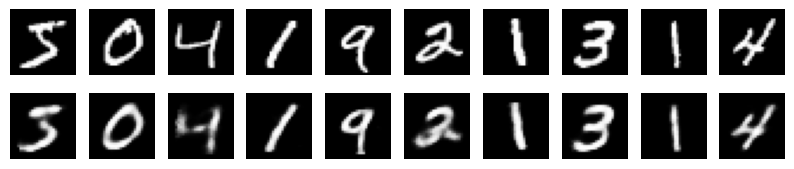

In [4]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load dataset
data = datasets.MNIST("data", train=True, download=True,
                      transform=transforms.ToTensor())
loader = DataLoader(data, batch_size=128, shuffle=True)

# 2. Define autoencoder
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32)
        )
        self.decoder = nn.Sequential(
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 784), nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Autoencoder().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# 3. Train
for epoch in range(10):
    total_loss = 0
    for images, _ in loader:
        images = images.flatten(1).to(device)
        optimizer.zero_grad()
        output = model(images)
        loss = loss_fn(output, images)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(loader):.4f}")

# 4. Display original and reconstructed images
model.eval()
images, _ = next(iter(DataLoader(data, batch_size=10)))
with torch.no_grad():
    output = model(images.flatten(1).to(device)).cpu().reshape(-1, 28, 28)

fig, axes = plt.subplots(2, 10, figsize=(10, 2))
for i in range(10):
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[1, i].imshow(output[i], cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.show()

# Experiment 5

In [5]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Load dataset
data = fetch_20newsgroups(
    subset="all", remove=("headers", "footers", "quotes")
)
texts, labels = data.data, data.target
classes = len(data.target_names)

# 2. Preprocess text
MAX_WORDS, MAX_LEN = 10000, 300
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
X = pad_sequences(tokenizer.texts_to_sequences(texts),
                  maxlen=MAX_LEN)
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Define LSTM model
model = Sequential([
    Embedding(MAX_WORDS, 64),
    LSTM(64),
    Dense(classes, activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# 4. Train and evaluate
model.fit(X_train, y_train, epochs=5, batch_size=64,
          validation_split=0.1)
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

Epoch 1/5
212/212 ━━━━━━━━━━━━━━━━━━━━ 63s 284ms/step - accuracy: 0.1170 - loss: 2.8647 - val_accuracy: 0.1678 - val_loss: 2.5582
Epoch 2/5
212/212 ━━━━━━━━━━━━━━━━━━━━ 65s 206ms/step - accuracy: 0.2273 - loss: 2.2888 - val_accuracy: 0.2513 - val_loss: 2.1585
Epoch 3/5
212/212 ━━━━━━━━━━━━━━━━━━━━ 82s 207ms/step - accuracy: 0.3331 - loss: 1.9752 - val_accuracy: 0.2752 - val_loss: 2.2978
Epoch 4/5
212/212 ━━━━━━━━━━━━━━━━━━━━ 44s 207ms/step - accuracy: 0.3993 - loss: 1.7734 - val_accuracy: 0.3541 - val_loss: 1.9180
Epoch 5/5
212/212 ━━━━━━━━━━━━━━━━━━━━ 82s 209ms/step - accuracy: 0.4985 - loss: 1.4939 - val_accuracy: 0.3985 - val_loss: 1.8337
118/118 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.4133 - loss: 1.8128
Test Accuracy: 41.33%


# Experiment 6

In [6]:
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Generate dataset
np.random.seed(42)
t = np.arange(1000)
series = 10 + 0.01*t + np.sin(2*np.pi*t/50) + 0.1*np.random.randn(1000)

# 2. Scale using training data only
split_time = 800
scaler = StandardScaler()
scaler.fit(series[:split_time].reshape(-1, 1))
scaled = scaler.transform(series.reshape(-1, 1)).flatten()

# 3. Create input and output windows
INPUT, OUTPUT = 30, 10
X, Y = [], []

for i in range(len(scaled) - INPUT - OUTPUT + 1):
    X.append(scaled[i:i+INPUT])
    Y.append(scaled[i+INPUT:i+INPUT+OUTPUT])

X, Y = np.array(X)[..., None], np.array(Y)
split = split_time - INPUT - OUTPUT + 1
X_train, X_test = X[:split], X[split:]
Y_train, Y_test = Y[:split], Y[split:]

# 4. Build LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(INPUT, 1)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(OUTPUT)
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.fit(X_train, Y_train, epochs=10, batch_size=32,
          validation_split=0.1, verbose=1)

# 5. Predict and evaluate
pred = model.predict(X_test)
pred = scaler.inverse_transform(pred.reshape(-1, 1)).reshape(pred.shape)
actual = scaler.inverse_transform(Y_test.reshape(-1, 1)).reshape(Y_test.shape)

print("MAE:", mean_absolute_error(actual.flatten(), pred.flatten()))
print("RMSE:", np.sqrt(mean_squared_error(actual.flatten(), pred.flatten())))

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.4025 - mae: 0.5098 - val_loss: 0.5087 - val_mae: 0.6384
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1633 - mae: 0.3430 - val_loss: 0.3285 - val_mae: 0.4969
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.1361 - mae: 0.3152 - val_loss: 0.1690 - val_mae: 0.3126
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1221 - mae: 0.2962 - val_loss: 0.1211 - val_mae: 0.2594
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1083 - mae: 0.2797 - val_loss: 0.1129 - val_mae: 0.2486
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0903 - mae: 0.2495 - val_loss: 0.1042 - val_mae: 0.2495
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0563 - mae: 0.1918 - val_loss: 0.1299 - val_mae: 0.3046
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0327 - mae: 0.1446 - val_loss: 0.1168 - val_mae: 0.2862
Epoch 9/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.018

# Experiment 7

In [10]:
!pip install -q importlib_resources tensorflow-datasets

In [11]:

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

# Download dataset
(train_ds, val_ds), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
    download=True
)

# Use subsets for faster training
train_ds = train_ds.take(2000)
val_ds = val_ds.take(500)

# Preprocess images
def prepare(image, label):
    image = tf.image.resize(image, (224, 224))
    return preprocess_input(tf.cast(image, tf.float32)), label

train_ds = train_ds.map(prepare).batch(32).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(prepare).batch(32).prefetch(tf.data.AUTOTUNE)

# Load pretrained ResNet50
base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base.trainable = False

# Classification layers
x = GlobalAveragePooling2D()(base.output)
x = Dense(128, activation="relu")(x)
output = Dense(2, activation="softmax")(x)
model = Model(base.input, output)

# Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_ds, validation_data=val_ds, epochs=3)

# Evaluate
loss, accuracy = model.evaluate(val_ds)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.RHRG86_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 478s 7s/step - accuracy: 0.9430 - loss: 0.1431 - val_accuracy: 0.9880 - val_loss: 0.0358
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 453s 7s/step - accuracy: 0.9940 - loss: 0.0237 - val_accuracy: 0.9900 - val_loss: 0.0297
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 518s 7s/step - accuracy: 0.9970 - loss: 0.0161 - val_accuracy: 0.9900 - val_loss: 0.0322
16/16 ━━━━━━━━━━━━━━━━━━━━ 91s 6s/step - accuracy: 0.9900 - loss: 0.0322
Validation Accuracy: 99.00%


# Experiment 8

In [7]:
import random

class GridWorld:
    def __init__(self):
        self.width = self.height = 5
        self.start, self.goal = (0, 0), (4, 4)
        positions = [(i, j) for i in range(5) for j in range(5)]
        positions.remove(self.start)
        positions.remove(self.goal)
        self.obstacles = random.sample(positions, 3)
        self.reset()

    def reset(self):
        self.agent = self.start

    def render(self):
        for i in range(5):
            row = ""
            for j in range(5):
                p = (i, j)
                if p == self.agent:
                    row += "A "
                elif p == self.start:
                    row += "S "
                elif p == self.goal:
                    row += "G "
                elif p in self.obstacles:
                    row += "O "
                else:
                    row += ". "
            print(row)
        print()

    def step(self, action):
        x, y = self.agent
        moves = {"up": (-1, 0), "down": (1, 0),
                 "left": (0, -1), "right": (0, 1)}

        if action not in moves:
            print("Invalid action!")
            return 0, False

        dx, dy = moves[action]
        new = (x + dx, y + dy)

        if not (0 <= new[0] < 5 and 0 <= new[1] < 5):
            new = self.agent

        self.agent = new

        if new in self.obstacles:
            return -1, True
        if new == self.goal:
            return 1, True
        return -0.01, False

env = GridWorld()
print("Reach G, avoid O. A = Agent, S = Start")
done = False
env.render()

while not done:
    action = input("Move (up/down/left/right): ").lower().strip()
    reward, done = env.step(action)
    print("Position:", env.agent, "Reward:", reward)
    env.render()

print("Congratulations!" if env.agent == env.goal else "Game Over!")

Reach G, avoid O. A = Agent, S = Start
A O . . . 
. . O . . 
. . . . . 
. . . . O 
. . . . G 

Move (up/down/left/right): up
Position: (0, 0) Reward: -0.01
A O . . . 
. . O . . 
. . . . . 
. . . . O 
. . . . G 

Move (up/down/left/right): left
Position: (0, 0) Reward: -0.01
A O . . . 
. . O . . 
. . . . . 
. . . . O 
. . . . G 

Move (up/down/left/right): right
Position: (0, 1) Reward: -1
S A . . . 
. . O . . 
. . . . . 
. . . . O 
. . . . G 

Game Over!
